In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("electricity_hourly_practice.csv", parse_dates=['timestamp'])
df

,timestamp,temperature_c,demand_mw,price_usd_mwh,temperature_c_squared,irrelevant_noise,next_hour_settlement_hint
0,2025-01-18 08:00:00,8.018191,1403.412912,51.590495,64.291392,0.211833,50.285099
1,2025-03-05 15:00:00,22.865890,1495.112289,55.894888,522.848903,-1.055988,55.584036
2,2025-01-14 17:00:00,17.591397,1551.805614,54.893502,309.457266,-0.184754,47.931006
3,2025-01-17 10:00:00,9.225438,1693.618343,51.193238,85.108699,-0.713473,50.039783
4,2025-01-17 11:00:00,12.121288,1584.844672,49.850475,146.925628,-0.218229,48.061384
...,...,...,...,...,...,...,...
2884,2025-03-12 17:00:00,18.875572,1497.145943,44.460433,356.287215,-0.944694,44.819116
2885,2025-01-14 20:00:00,17.154807,1374.276524,38.956974,294.287415,-1.126932,34.395105
2886,2025-02-23 21:00:00,3.157413,1295.344960,58.042694,9.969254,-1.363784,62.351532
2887,2025-02-16 00:00:00,6.829154,1229.341041,41.136887,46.637345,0.424918,50.985225


In [6]:
df.sort_values(by='timestamp',inplace=True)
df

,timestamp,temperature_c,demand_mw,price_usd_mwh,temperature_c_squared,irrelevant_noise,next_hour_settlement_hint
2710,2025-01-01 00:00:00,9.910708,1417.668873,52.000000,98.222127,0.126962,52.072801
498,2025-01-01 01:00:00,10.101396,1350.931325,52.099484,102.038192,0.783672,56.662881
521,2025-01-01 02:00:00,NaN,1465.505371,56.598671,79.865986,0.141673,48.764667
2507,2025-01-01 03:00:00,9.889367,1455.437150,49.030935,97.799584,0.748821,58.743126
2184,2025-01-01 04:00:00,11.345811,1477.948258,58.806042,128.727421,-0.821246,53.098128
...,...,...,...,...,...,...,...
2040,2025-04-30 19:00:00,14.468400,1406.962206,40.861263,209.334599,0.643079,44.084030
2106,2025-04-30 20:00:00,13.536381,1443.968411,44.167921,183.233598,2.028793,44.560417
2271,2025-04-30 21:00:00,13.354557,1452.157144,44.482844,178.344194,-0.226752,45.204349
2315,2025-04-30 22:00:00,11.043468,1494.601157,45.114305,121.958183,0.282989,49.785148


In [9]:
df.describe()

,timestamp,temperature_c,demand_mw,price_usd_mwh,temperature_c_squared,irrelevant_noise,next_hour_settlement_hint
count,2889,2813.000000,2844.000000,2854.000000,2889.000000,2889.000000,2888.000000
mean,2025-03-01 22:50:14.330218240,12.965046,1454.645175,51.538965,211.612170,-0.002269,51.498725
min,2025-01-01 00:00:00,-5.007969,1133.058477,-27.603386,0.006351,-3.730426,-29.116872
25%,2025-01-30 23:00:00,7.632404,1385.356136,46.851473,58.799680,-0.659767,46.810465
50%,2025-03-01 22:00:00,13.030670,1461.568769,51.430077,171.190083,0.001515,51.408447
75%,2025-03-31 22:00:00,18.268909,1534.393941,56.082155,336.042746,0.647380,56.076309
max,2025-04-30 23:00:00,28.761274,1698.187012,119.378558,827.210909,3.632962,119.465189
std,NaN,6.458250,106.290106,8.299197,173.542761,0.986651,8.420658


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2889 entries, 2710 to 2626
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   timestamp                  2889 non-null   datetime64[ns]
 1   temperature_c              2813 non-null   float64       
 2   demand_mw                  2844 non-null   float64       
 3   price_usd_mwh              2854 non-null   float64       
 4   temperature_c_squared      2889 non-null   float64       
 5   irrelevant_noise           2889 non-null   float64       
 6   next_hour_settlement_hint  2888 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 180.6 KB


In [11]:
print('Raw shape:', df.shape)
print('Column types:\n', df.dtypes.to_string())
print('Missing ratios:\n', df.isna().mean().round(3).to_string())
print('Duplicate timestamps:', df['timestamp'].duplicated().sum())
df = df.sort_values('timestamp').drop_duplicates('timestamp', keep='first').reset_index(drop=True)

Raw shape: (2889, 7)
Column types:
 timestamp                    datetime64[ns]
temperature_c                       float64
demand_mw                           float64
price_usd_mwh                       float64
temperature_c_squared               float64
irrelevant_noise                    float64
next_hour_settlement_hint           float64
Missing ratios:
 timestamp                    0.000
temperature_c                0.026
demand_mw                    0.016
price_usd_mwh                0.012
temperature_c_squared        0.000
irrelevant_noise             0.000
next_hour_settlement_hint    0.000
Duplicate timestamps: 9


In [12]:
valid = df['temperature_c'].notna() & df['temperature_c_squared'].notna()
wrong = valid & ~np.isclose(df['temperature_c_squared'], df['temperature_c']**2, atol=1e-6, rtol=1e-6)
print('Inconsistent temperature-squared entries:', wrong.sum())

Inconsistent temperature-squared entries: 29


In [13]:
# 3. TARGET: the observed next-hour market price. Never fill missing targets.
df['target_next_hour'] = df['price_usd_mwh'].shift(-1)
# Only historical/current prices can be used as predictors.
# Forward-fill feature prices CAUSALLY; this must happen after ordering timestamps.
df['known_price_at_t'] = df['price_usd_mwh'].ffill()
df['price_lag_1'] = df['known_price_at_t'].shift(1)
df['price_lag_24'] = df['known_price_at_t'].shift(24)
df['price_lag_168'] = df['known_price_at_t'].shift(168)
# Trailing statistics ONLY (no centered rolling windows).
df['price_ma_24'] = df['known_price_at_t'].rolling(24, min_periods=24).mean()
df['price_std_24'] = df['known_price_at_t'].rolling(24, min_periods=24).std()
# Time-of-day at target timestamp (t+1) is known at prediction time.
future_time = df['timestamp'] + pd.Timedelta(hours=1)
df['next_hour_sin'] = np.sin(2 * np.pi * future_time.dt.hour / 24)
df['next_hour_cos'] = np.cos(2 * np.pi * future_time.dt.hour / 24)
df['next_dow'] = future_time.dt.dayofweek

In [14]:
FEATURES = ['known_price_at_t', 'price_lag_1', 'price_lag_24', 'price_lag_168',
            'price_ma_24', 'price_std_24', 'temperature_c', 'demand_mw',
            'next_hour_sin', 'next_hour_cos', 'next_dow']
# Drop history warm-up and rows without REAL target measurements.
model_df = df.iloc[168:].dropna(subset=['target_next_hour', 'known_price_at_t']).copy()
assert len(model_df) > 1000
assert 'next_hour_settlement_hint' not in FEATURES

In [15]:
# 4. Chronological 60/20/20 split (test remains untouched until final).
n = len(model_df)
i_train, i_val = int(n*0.6), int(n*0.8)
# One-row purge: final train label would fall inside the validation period;
# final validation label would fall inside the test period.
train = model_df.iloc[:i_train-1]
val = model_df.iloc[i_train:i_val-1]
test = model_df.iloc[i_val:]
print('Train/val/test:', len(train), len(val), len(test))
print('Ranges:', train['timestamp'].min(), train['timestamp'].max(), ' | ',
      val['timestamp'].min(), val['timestamp'].max(), ' | ',
      test['timestamp'].min(), test['timestamp'].max())

Train/val/test: 1605 534 536
Ranges: 2025-01-08 00:00:00 2025-03-16 17:00:00  |  2025-03-16 19:00:00 2025-04-08 07:00:00  |  2025-04-08 09:00:00 2025-04-30 22:00:00


In [22]:
# 5. EDA on TRAIN ONLY (distribution and seasonal decomposition).
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
train['price_usd_mwh'].plot(ax=ax[0], title='Train: hourly electricity price')
train['price_usd_mwh'].dropna().hist(bins=50, ax=ax[1])
ax[1].set_title('Train: price distribution')
fig.tight_layout()
fig.savefig('output_2/eda_train.png',dpi=300)
plt.close(fig)
observed_train = df.loc[df['timestamp'].between(train['timestamp'].min(), train['timestamp'].max()),
                        'price_usd_mwh'].ffill().bfill().to_numpy()

            timestamp  temperature_c    demand_mw  price_usd_mwh  \
0 2025-01-01 00:00:00       9.910708  1417.668873      52.000000   
1 2025-01-01 01:00:00      10.101396  1350.931325      52.099484   
2 2025-01-01 02:00:00            NaN  1465.505371      56.598671   
3 2025-01-01 03:00:00       9.889367  1455.437150      49.030935   
4 2025-01-01 04:00:00      11.345811  1477.948258      58.806042   

   temperature_c_squared  irrelevant_noise  next_hour_settlement_hint  \
0              98.222127          0.126962                  52.072801   
1             102.038192          0.783672                  56.662881   
2              79.865986          0.141673                  48.764667   
3              97.799584          0.748821                  58.743126   
4             128.727421         -0.821246                  53.098128   

   target_next_hour  known_price_at_t  price_lag_1  price_lag_24  \
0         52.099484         52.000000          NaN           NaN   
1         56.598

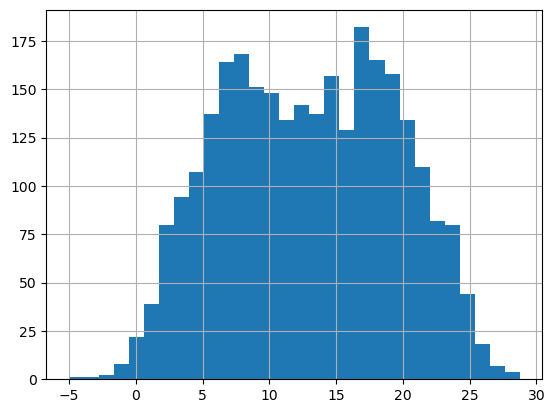

                           temperature_c  demand_mw  price_usd_mwh  \
temperature_c                   1.000000  -0.066516      -0.069707   
demand_mw                      -0.066516   1.000000       0.358982   
price_usd_mwh                  -0.069707   0.358982       1.000000   
temperature_c_squared           0.968211  -0.056270      -0.069165   
irrelevant_noise               -0.011841   0.033192       0.004511   
next_hour_settlement_hint      -0.097270   0.299926       0.474208   
target_next_hour               -0.099535   0.302978       0.486663   
known_price_at_t               -0.068294   0.357391       1.000000   
price_lag_1                    -0.018351   0.363684       0.478669   
price_lag_24                   -0.047089   0.202487       0.222449   
price_lag_168                   0.062096   0.295178       0.218718   
price_ma_24                    -0.244949   0.303952       0.283946   
price_std_24                    0.047300   0.138834       0.042930   
next_hour_sin       

In [24]:
# Understand the dataset
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

# Missing values
print(df.isna().sum())

# Duplicate rows
print(df.duplicated().sum())

# Distribution
df["temperature_c"].hist(bins=30)
plt.show()

# Correlation
print(df.corr(numeric_only=True))